In [173]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import accuracy_score,mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold   
from sklearn.metrics import f1_score, roc_auc_score 

In [174]:
pip install pandas numpy scikit-learn matplotlib seaborn xgboost

Note: you may need to restart the kernel to use updated packages.


In [175]:
df = pd.read_csv("/run/media/pravesh/Data2/ML_Lab_Project/datasets/cancer_patients_tabular.csv")


In [176]:
df.shape

(9523, 17)

## 1. Dataset Overview

In [177]:
df.head()

,patient_id,age,sex,race,ethnicity,histology_code,tumor_stage,t_stage,n_stage,m_stage,radiation_therapy,new_tumor_event,survival_status,survival_months,cancer_type,cancer_name,organ
0,TCGA-BP-5195,75.0,Male,White,Not Hispanic Or Latino,8310/3,STAGE I,T1A,NX,M0,NaN,NaN,LIVING,24.624388,KIRC,Kidney renal clear cell carcinoma,Kidney
1,TCGA-D7-8573,57.0,Male,White,Not Hispanic Or Latino,8211/3,STAGE IIA,T3,N0,M0,No,No,LIVING,19.495677,STAD,Stomach adenocarcinoma,Stomach
2,TCGA-EI-7004,37.0,Female,White,Not Hispanic Or Latino,8480/3,STAGE IVA,T4A,N2B,M0,No,No,LIVING,8.449222,READ,Rectum adenocarcinoma,Colorectal
3,TCGA-EB-A82B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SKCM,Skin cutaneous melanoma,Skin
4,TCGA-A6-3808,73.0,Male,White,Not Hispanic Or Latino,8140/3,STAGE IIA,T3,N0,M0,No,No,LIVING,33.336621,COAD,Colon adenocarcinoma,Colorectal


In [178]:
df.tail()

,patient_id,age,sex,race,ethnicity,histology_code,tumor_stage,t_stage,n_stage,m_stage,radiation_therapy,new_tumor_event,survival_status,survival_months,cancer_type,cancer_name,organ
9518,TCGA-GM-A3XL,49.0,Female,Black or African American,Not Hispanic Or Latino,8500/3,STAGE IIA,T2,N0 (I-),M0,Yes,No,LIVING,69.303350,BRCA,Breast invasive carcinoma,Breast
9519,TCGA-B5-A1MY,62.0,Female,Black or African American,NaN,8441/3,NaN,NaN,NaN,NaN,Yes,Yes,DECEASED,11.868363,UCEC,Uterine corpus endometrial carcinoma,Uterus
9520,TCGA-DJ-A2Q7,52.0,Female,Asian,Not Hispanic Or Latino,8260/3,STAGE III,T2,N1A,M0,No,No,LIVING,35.111944,THCA,Thyroid carcinoma,Thyroid
9521,TCGA-CK-4948,45.0,Female,White,Not Hispanic Or Latino,8140/3,STAGE III,T3,N1,M0,No,No,LIVING,148.009337,COAD,Colon adenocarcinoma,Colorectal
9522,TCGA-AA-3538,54.0,Female,NaN,NaN,8140/3,STAGE I,T2,N0,M0,No,No,LIVING,26.005194,COAD,Colon adenocarcinoma,Colorectal


In [179]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9523 entries, 0 to 9522
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         9523 non-null   str    
 1   age                9258 non-null   float64
 2   sex                9281 non-null   str    
 3   race               8115 non-null   str    
 4   ethnicity          6958 non-null   str    
 5   histology_code     9280 non-null   str    
 6   tumor_stage        5971 non-null   str    
 7   t_stage            6757 non-null   str    
 8   n_stage            6708 non-null   str    
 9   m_stage            5944 non-null   str    
 10  radiation_therapy  7123 non-null   str    
 11  new_tumor_event    6715 non-null   str    
 12  survival_status    9280 non-null   str    
 13  survival_months    9232 non-null   float64
 14  cancer_type        9523 non-null   str    
 15  cancer_name        9523 non-null   str    
 16  organ              9523 non-null   

In [180]:
df.columns

Index(['patient_id', 'age', 'sex', 'race', 'ethnicity', 'histology_code',
       'tumor_stage', 't_stage', 'n_stage', 'm_stage', 'radiation_therapy',
       'new_tumor_event', 'survival_status', 'survival_months', 'cancer_type',
       'cancer_name', 'organ'],
      dtype='str')

## 2. Identifying datatypes of columns in the Dataset

In [181]:
df.dtypes

patient_id               str
age                  float64
sex                      str
race                     str
ethnicity                str
histology_code           str
tumor_stage              str
t_stage                  str
n_stage                  str
m_stage                  str
radiation_therapy        str
new_tumor_event          str
survival_status          str
survival_months      float64
cancer_type              str
cancer_name              str
organ                    str
dtype: object

## 3. Descriptive statistics of numerical columns

In [182]:
df.describe()#statistics about the numerical columns in the dataset

,age,survival_months
count,9258.000000,9232.000000
mean,59.482610,32.983545
std,14.188859,31.207418
min,14.000000,0.000000
25%,51.000000,12.743287
50%,61.000000,23.572344
75%,70.000000,43.692672
max,90.000000,316.730776


## 4. Identify and handle missing values

In [183]:
df.isnull().sum()#checking for missing values in the dataset

patient_id              0
age                   265
sex                   242
race                 1408
ethnicity            2565
histology_code        243
tumor_stage          3552
t_stage              2766
n_stage              2815
m_stage              3579
radiation_therapy    2400
new_tumor_event      2808
survival_status       243
survival_months       291
cancer_type             0
cancer_name             0
organ                   0
dtype: int64

In [184]:
#separating numerical and categorical columns for handling missing values and feature scaling in further steps
numerical_cols = df.select_dtypes(include=['float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

/tmp/ipykernel_131299/3770210914.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


In [185]:
numerical_cols, categorical_cols

(['age', 'survival_months'],
 ['patient_id',
  'sex',
  'race',
  'ethnicity',
  'histology_code',
  'tumor_stage',
  't_stage',
  'n_stage',
  'm_stage',
  'radiation_therapy',
  'new_tumor_event',
  'survival_status',
  'cancer_type',
  'cancer_name',
  'organ'])

In [186]:
df[numerical_cols].isnull().sum()

age                265
survival_months    291
dtype: int64

Mean  : 59.48260963491035
Median: 61.0
Skew  : -0.4410183731470825


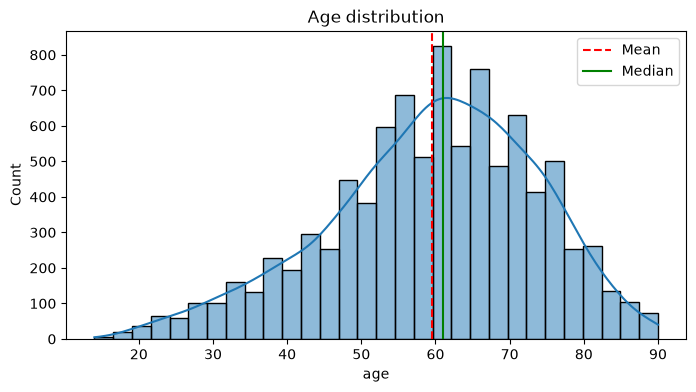

In [187]:
print('Mean  :', df['age'].mean())
print('Median:', df['age'].median())
print('Skew  :', df['age'].skew())

plt.figure(figsize=(8, 4))
sns.histplot(df['age'], kde=True, bins=30)
plt.axvline(df['age'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(df['age'].median(), color='green', linestyle='-', label='Median')
plt.legend(); plt.title('Age distribution'); plt.show()

In [188]:
df['age'] = df['age'].fillna(df['age'].median())#used median becuase 61 is a whole number and skewness is > -0.5
df['age'].isnull().sum()

np.int64(0)

In [189]:
remove = ['patient_id', 'survival_status', 'cancer_type', 'cancer_name', 'organ']
for i in remove:
    if i in categorical_cols:
        categorical_cols.remove(i)
categorical_cols

['sex',
 'race',
 'ethnicity',
 'histology_code',
 'tumor_stage',
 't_stage',
 'n_stage',
 'm_stage',
 'radiation_therapy',
 'new_tumor_event']

In [190]:
x = ((df[categorical_cols].isnull().sum() / len(df)) * 100).sort_values()#missing values in categorical columns in percentage
x

sex                   2.541216
histology_code        2.551717
race                 14.785257
radiation_therapy    25.202142
ethnicity            26.934789
t_stage              29.045469
new_tumor_event      29.486506
n_stage              29.560013
tumor_stage          37.299170
m_stage              37.582695
dtype: float64

In [191]:
for i in categorical_cols:
    missing = df[i].isnull().sum()/ len(df[i]) * 100
    if missing < 5:
        df[i] = df[i].fillna(df[i].mode()[0])
    else:
        df[i] = df[i].fillna('Unknown')
df[categorical_cols].isnull().sum()

sex                  0
race                 0
ethnicity            0
histology_code       0
tumor_stage          0
t_stage              0
n_stage              0
m_stage              0
radiation_therapy    0
new_tumor_event      0
dtype: int64

## 5. Identifying and handling duplicates 

In [192]:

df.nunique()

patient_id           9523
age                    77
sex                     2
race                   11
ethnicity               5
histology_code        130
tumor_stage            29
t_stage                37
n_stage                19
m_stage                10
radiation_therapy       5
new_tumor_event         3
survival_status         2
survival_months      3540
cancer_type            32
cancer_name            32
organ                  23
dtype: int64

In [193]:
df.duplicated().sum()#checking for duplicates

np.int64(0)

## 6. Identify and handle outliers

<Axes: xlabel='age'>

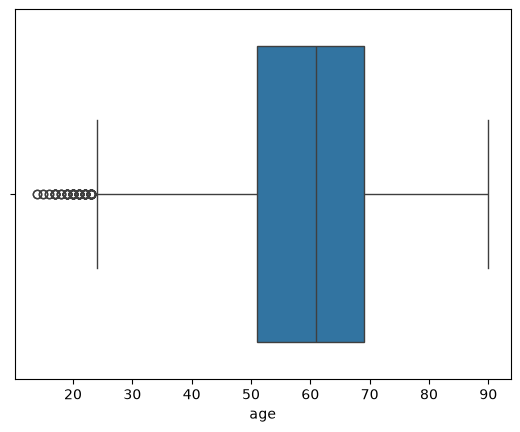

In [194]:
sns.boxplot(x=df['age'])

In [195]:
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['age'] < lower_bound) | (df['age'] > upper_bound)]

Outliers removed: 101


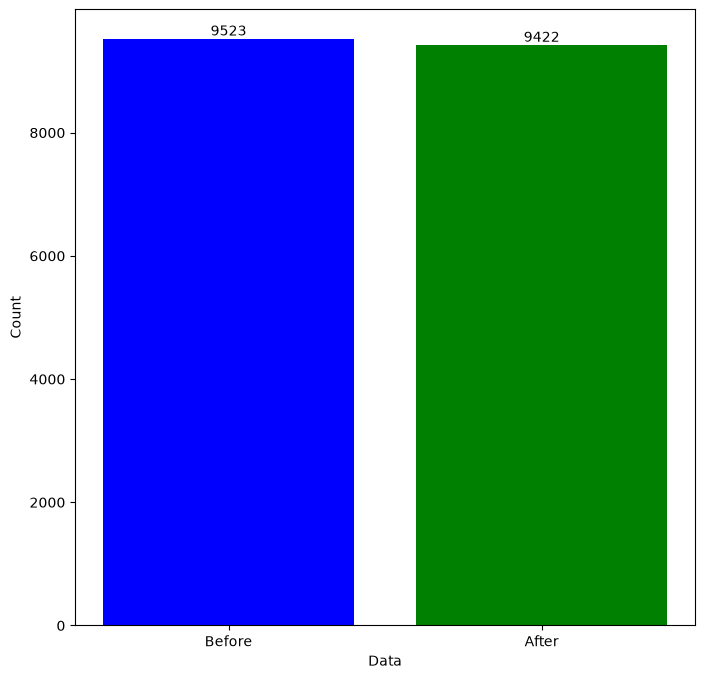

In [196]:
figure = plt.figure(figsize=(8, 8))
df_no_outliers = df[(df['age'] >= lower_bound) & (df['age'] <= upper_bound)]
a = plt.bar(['Before', 'After'], [len(df), len(df_no_outliers)], color=['blue', 'green'])
plt.bar_label(a)
plt.xlabel('Data')
plt.ylabel('Count')
print("Outliers removed:", len(df) - len(df_no_outliers))

## 7. Visulaizations of columns and their relations

Text(0.5, 1.0, 'Age Distribution by Gender')

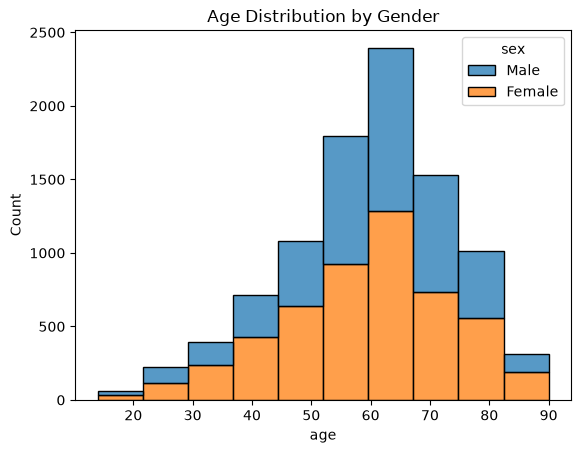

In [197]:
sns.histplot(data=df, x='age', hue='sex', multiple='stack', bins=10,)
plt.title('Age Distribution by Gender')

Text(0.5, 1.0, 'Organ cancer by Gender')

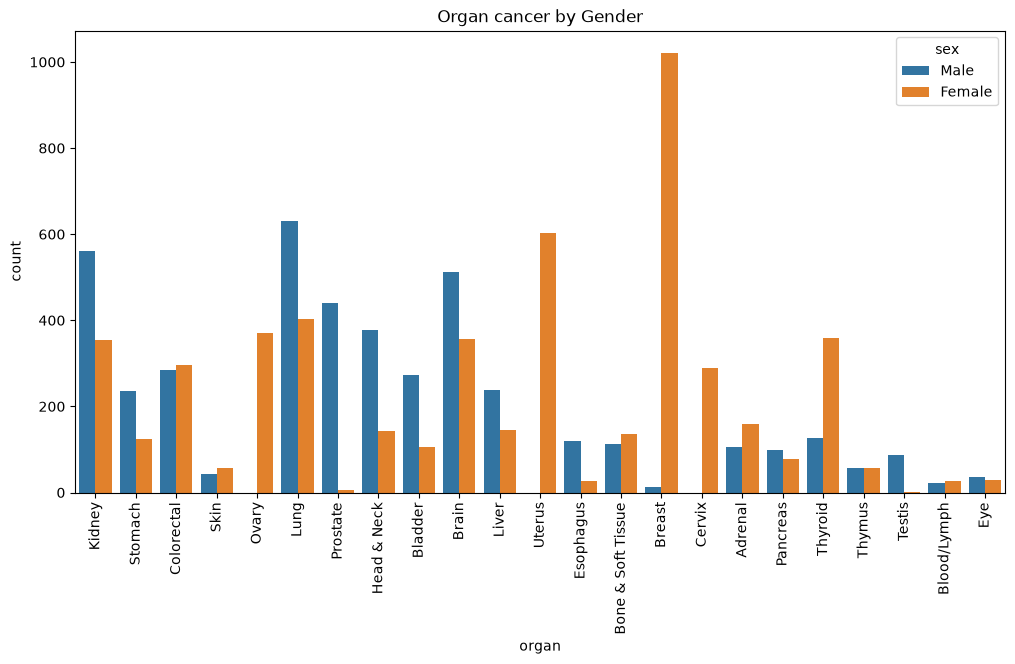

In [198]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='organ', hue='sex')
plt.xticks(rotation=90)
plt.title('Organ cancer by Gender')

Text(0.5, 1.0, 'Sex vs Survival Status')

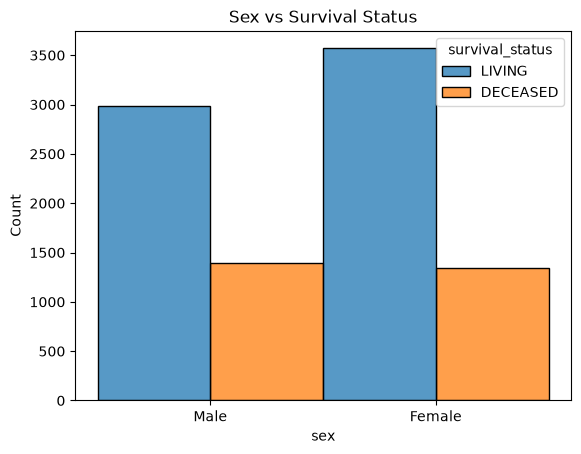

In [199]:
sns.histplot(data=df, x='sex', hue='survival_status', multiple='dodge', bins=15)
plt.title('Sex vs Survival Status')

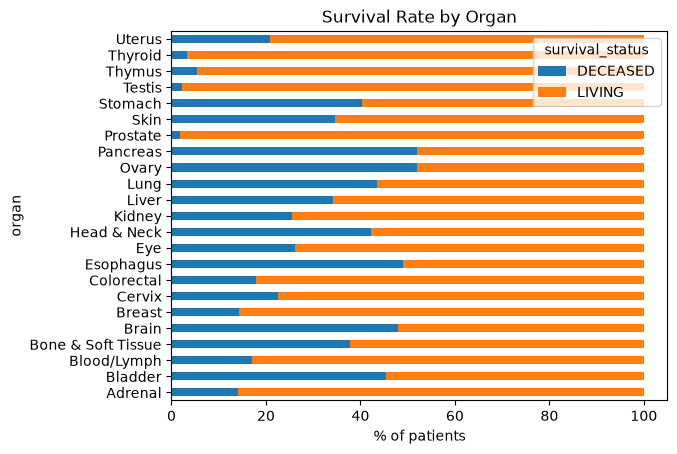

In [200]:
pd.crosstab(df['organ'], df['survival_status'], normalize='index').mul(100).plot(kind='barh', stacked=True)#which cancer has caused more deaths
plt.xlabel('% of patients'); plt.title('Survival Rate by Organ'); plt.show()

## 8.Scaling Numerical features and Encoding Categorical values and Model Training

In [201]:
df.columns

Index(['patient_id', 'age', 'sex', 'race', 'ethnicity', 'histology_code',
       'tumor_stage', 't_stage', 'n_stage', 'm_stage', 'radiation_therapy',
       'new_tumor_event', 'survival_status', 'survival_months', 'cancer_type',
       'cancer_name', 'organ'],
      dtype='str')

In [202]:
X_1 = df.drop(columns=[
    'patient_id', 'survival_status', 'survival_months',
    'cancer_type', 'cancer_name', 'organ', 'ethnicity', 'race'
])
y_1 = df['organ']


In [203]:
X_1_train, X_1_test, y_1_train, y_1_test = train_test_split(X_1, y_1, test_size=0.2, random_state=42)

In [204]:
nums_col = ['age']
cate_col = ['sex', 'histology_code', 'tumor_stage', 't_stage', 'n_stage',
            'm_stage', 'radiation_therapy', 'new_tumor_event']#preprocessing


In [205]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), nums_col),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cate_col)
])

In [206]:
X_1_train_encoded = preprocessor.fit_transform(X_1_train)
X_1_test_encoded  = preprocessor.transform(X_1_test)

In [207]:
le = LabelEncoder()
y_1_train_encoded = le.fit_transform(y_1_train)
y_1_test_encoded = le.transform(y_1_test)

## 8.1 Training model for predicting "Organ"

In [208]:
results = {}
lr = LogisticRegression(max_iter=2000)
lr.fit(X_1_train_encoded, y_1_train_encoded)
p1 = lr.predict(X_1_test_encoded)
results['Logistic Regression'] = accuracy_score(y_1_test_encoded, p1)

In [209]:
knn = KNeighborsClassifier()
knn.fit(X_1_train_encoded, y_1_train_encoded)
p2 = knn.predict(X_1_test_encoded)
results['KNN'] = accuracy_score(y_1_test_encoded, p2)

In [210]:
svc = SVC(random_state=42)
svc.fit(X_1_train_encoded, y_1_train_encoded)
p3 = svc.predict(X_1_test_encoded)
results['SVC'] = accuracy_score(y_1_test_encoded, p3)

In [211]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_1_train_encoded, y_1_train_encoded)
p4 = dt.predict(X_1_test_encoded)
results['Decision Tree'] = accuracy_score(y_1_test_encoded, p4)

In [212]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_1_train_encoded, y_1_train_encoded)
p5 = rf.predict(X_1_test_encoded)
results['Random Forest'] = accuracy_score(y_1_test_encoded, p5)

In [213]:
xgb = XGBClassifier(random_state=42)
xgb.fit(X_1_train_encoded, y_1_train_encoded)
p6 = xgb.predict(X_1_test_encoded)
results['XGBoost'] = accuracy_score(y_1_test_encoded, p6)

In [214]:
best_acc = max(results.values())
for i in results:
    if results[i] == best_acc:
        print(f"Best model is {i} with accuracy {best_acc:.4f}")

Best model is Logistic Regression with accuracy 0.9370


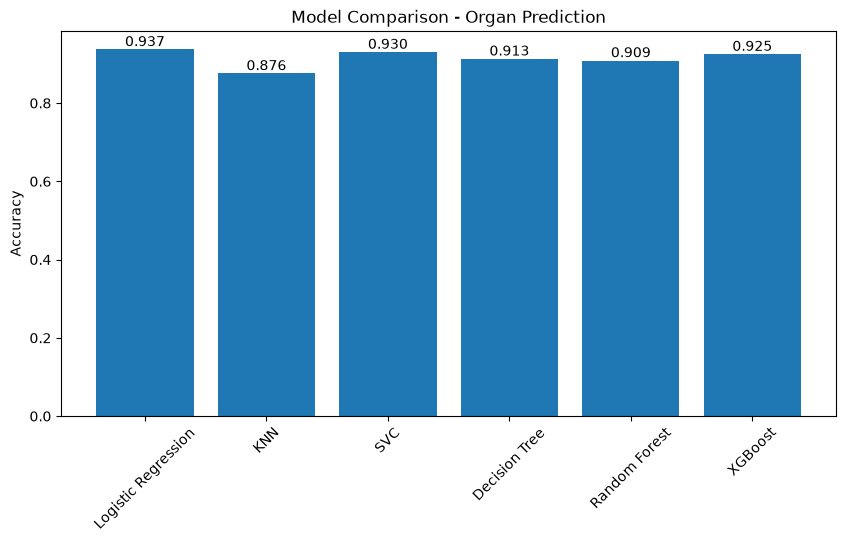

In [215]:
plt.figure(figsize=(10, 5))
bars = plt.bar(results.keys(), results.values())
plt.bar_label(bars, fmt='%.3f')
plt.xticks(rotation=45); plt.ylabel('Accuracy'); plt.title('Model Comparison - Organ Prediction')
plt.show()

In [216]:
print(classification_report(y_1_test_encoded, p5,
                            labels=range(len(le.classes_)),
                            target_names=le.classes_, zero_division=0))

                    precision    recall  f1-score   support

           Adrenal       1.00      0.90      0.95        59
           Bladder       1.00      1.00      1.00        84
       Blood/Lymph       1.00      1.00      1.00         8
Bone & Soft Tissue       1.00      0.87      0.93        54
             Brain       0.93      0.99      0.96       174
            Breast       0.99      0.98      0.98       204
            Cervix       0.98      0.88      0.93        51
        Colorectal       0.84      0.76      0.80       127
         Esophagus       0.64      0.28      0.39        32
               Eye       1.00      1.00      1.00        10
       Head & Neck       0.95      0.95      0.95       111
            Kidney       0.79      0.99      0.88       185
             Liver       0.96      0.95      0.95        76
              Lung       0.83      0.91      0.87       202
             Ovary       0.89      0.97      0.93        68
          Pancreas       0.96      0.78

In [217]:
import joblib

joblib.dump(rf, 'organ_model.pkl')
joblib.dump(preprocessor, 'organ_preprocessor.pkl')
joblib.dump(le, 'organ_label_encoder.pkl')

['organ_label_encoder.pkl']

## 8.2 Training Model for predicting "Stage"

In [218]:
df_2 = df[df['tumor_stage'] != 'Unknown'].copy()
df_2['stage'] = df_2['tumor_stage'].str.upper().str.extract(r'(STAGE IV|STAGE III|STAGE II|STAGE I)')[0]
df_2 = df_2.dropna(subset=['stage'])

In [219]:
X_2 = df_2.drop(columns=['patient_id', 'survival_status', 'survival_months',
                         'cancer_type', 'cancer_name', 'ethnicity', 'race',
                         'tumor_stage', 't_stage', 'n_stage', 'm_stage', 'stage'])
y_2 = df_2['stage']

In [220]:
print(df_2.shape)
print(df_2['stage'].value_counts())
X_2.columns

(5957, 18)
stage
STAGE II     1884
STAGE I      1856
STAGE III    1430
STAGE IV      787
Name: count, dtype: int64


Index(['age', 'sex', 'histology_code', 'radiation_therapy', 'new_tumor_event',
       'organ'],
      dtype='str')

In [221]:
X_2_train, X_2_test, y_2_train, y_2_test = train_test_split(X_2, y_2, test_size=0.2, random_state=42)

In [222]:
nums_col_2 = ['age']
cate_col_2 = ['sex', 'histology_code', 'radiation_therapy', 'new_tumor_event','organ']#preprocessing

In [223]:
preprocessor_2 = ColumnTransformer([
    ('num', StandardScaler(), nums_col_2),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cate_col_2)])

In [224]:
X_2_train_encoded = preprocessor_2.fit_transform(X_2_train)
X_2_test_encoded  = preprocessor_2.transform(X_2_test)

In [225]:
le_2 = LabelEncoder()
y_2_train_encoded = le_2.fit_transform(y_2_train)
y_2_test_encoded = le_2.transform(y_2_test)

In [226]:
results_2 = {}
lr = LogisticRegression(max_iter=2000)
lr.fit(X_2_train_encoded, y_2_train_encoded)
p1_1 = lr.predict(X_2_test_encoded)
results_2['Logistic Regression'] = accuracy_score(y_2_test_encoded, p1_1)

In [227]:
knn_1 = KNeighborsClassifier()
knn.fit(X_2_train_encoded, y_2_train_encoded)
p2_1 = knn.predict(X_2_test_encoded)
results_2['KNN'] = accuracy_score(y_2_test_encoded, p2_1)

In [228]:
svc_1 = SVC(random_state=42)
svc_1.fit(X_2_train_encoded, y_2_train_encoded)
p3_1 = svc_1.predict(X_2_test_encoded)
results_2['SVC'] = accuracy_score(y_2_test_encoded, p3_1)

In [229]:
dt_1 = DecisionTreeClassifier(random_state=42)
dt_1.fit(X_2_train_encoded, y_2_train_encoded)
p4_1 = dt_1.predict(X_2_test_encoded)
results_2['Decision Tree'] = accuracy_score(y_2_test_encoded, p4_1)

In [230]:
rf_1 = RandomForestClassifier(n_estimators=300, random_state=42)
rf_1.fit(X_2_train_encoded, y_2_train_encoded)
p5_1 = rf_1.predict(X_2_test_encoded)
results_2['Random Forest'] = accuracy_score(y_2_test_encoded, p5_1)

In [231]:
xgb_1 = XGBClassifier(random_state=42)
xgb_1.fit(X_2_train_encoded, y_2_train_encoded)
p6_1 = xgb_1.predict(X_2_test_encoded)
results_2['XGBoost'] = accuracy_score(y_2_test_encoded, p6_1)

In [232]:
for i in results_2:
    print(f"{i} predictions: {results_2[i]}")

Logistic Regression predictions: 0.5176174496644296
KNN predictions: 0.462248322147651
SVC predictions: 0.511744966442953
Decision Tree predictions: 0.44966442953020136
Random Forest predictions: 0.4597315436241611
XGBoost predictions: 0.5067114093959731


In [233]:
best_acc_2 = max(results_2.values())
for i in results_2:
    if results_2[i] == best_acc_2:
        print(f"Best model is {i} with accuracy {best_acc_2:.4f}")

Best model is Logistic Regression with accuracy 0.5176


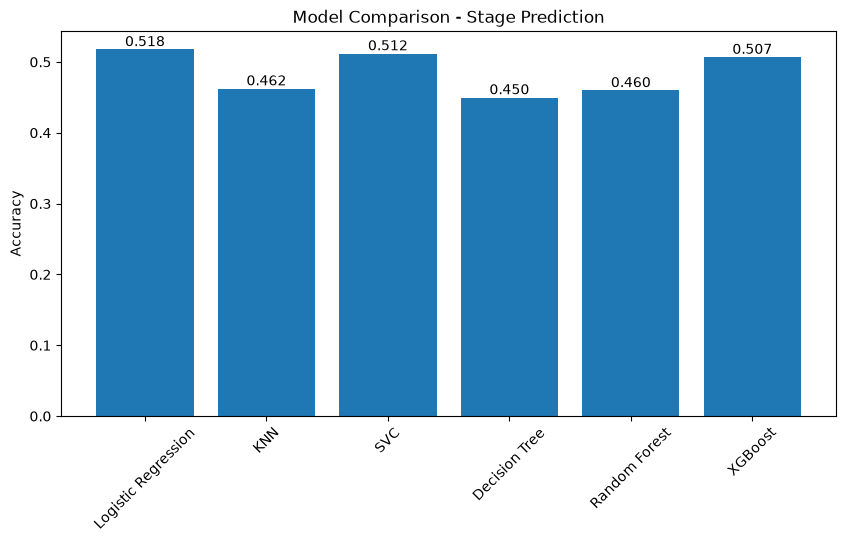

In [234]:
plt.figure(figsize=(10, 5))
bars = plt.bar(results_2.keys(), results_2.values())
plt.bar_label(bars, fmt='%.3f')
plt.xticks(rotation=45); plt.ylabel('Accuracy'); plt.title('Model Comparison - Stage Prediction')
plt.show()

In [235]:
print(classification_report(y_2_test_encoded, p1_1, target_names=le_2.classes_))

              precision    recall  f1-score   support

     STAGE I       0.56      0.74      0.64       366
    STAGE II       0.51      0.56      0.53       371
   STAGE III       0.39      0.25      0.31       296
    STAGE IV       0.57      0.42      0.48       159

    accuracy                           0.52      1192
   macro avg       0.51      0.49      0.49      1192
weighted avg       0.50      0.52      0.50      1192



In [236]:
joblib.dump(lr, 'stage_model.pkl')
joblib.dump(preprocessor_2, 'stage_preprocessor.pkl')
joblib.dump(le_2, 'stage_label_encoder.pkl')

['stage_label_encoder.pkl']

## 8.3 Training Model for predicting "Survival"

In [237]:
df_3 = df[df['survival_status'].notna() & (df['survival_status'] != 'Unknown')].copy()

print(df_3.shape)
df_3['survival_status'].value_counts()

(9280, 17)


survival_status
LIVING      6552
DECEASED    2728
Name: count, dtype: int64

In [238]:
X_3 = df_3.drop(columns=['patient_id', 'survival_status', 'survival_months',
                         'cancer_type', 'cancer_name', 'ethnicity', 'race'])
y_3 = df_3['survival_status']
X_3.columns

Index(['age', 'sex', 'histology_code', 'tumor_stage', 't_stage', 'n_stage',
       'm_stage', 'radiation_therapy', 'new_tumor_event', 'organ'],
      dtype='str')

In [239]:
X_3_train, X_3_test, y_3_train, y_3_test = train_test_split(X_3, y_3, test_size=0.2, random_state=42, stratify=y_3)

In [240]:
nums_col_3 = ['age']
cate_col_3 = ['sex', 'histology_code', 'tumor_stage', 't_stage', 'n_stage',
              'm_stage', 'radiation_therapy', 'new_tumor_event', 'organ']

In [241]:
preprocessor_3 = ColumnTransformer([
    ('num', StandardScaler(), nums_col_3),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cate_col_3)
])

In [242]:
X_3_train_encoded = preprocessor_3.fit_transform(X_3_train)
X_3_test_encoded  = preprocessor_3.transform(X_3_test)

In [243]:
le_3 = LabelEncoder()
y_3_train_encoded = le_3.fit_transform(y_3_train)
y_3_test_encoded  = le_3.transform(y_3_test)

In [244]:
results_3 = {}
lr_3 = LogisticRegression(max_iter=2000)
lr_3.fit(X_3_train_encoded, y_3_train_encoded)
p1_2 = lr_3.predict(X_3_test_encoded)
results_3['Logistic Regression'] = accuracy_score(y_3_test_encoded, p1_2)

In [245]:
knn_3 = KNeighborsClassifier()
knn_3.fit(X_3_train_encoded, y_3_train_encoded)
p2_2 = knn_3.predict(X_3_test_encoded)
results_3['KNN'] = accuracy_score(y_3_test_encoded, p2_2)

In [246]:
svc_3 = SVC(random_state=42)
svc_3.fit(X_3_train_encoded, y_3_train_encoded)
p3_2 = svc_3.predict(X_3_test_encoded)
results_3['SVC'] = accuracy_score(y_3_test_encoded, p3_2)

In [247]:
dt_3 = DecisionTreeClassifier(random_state=42)
dt_3.fit(X_3_train_encoded, y_3_train_encoded)
p4_2 = dt_3.predict(X_3_test_encoded)
results_3['Decision Tree'] = accuracy_score(y_3_test_encoded, p4_2)

In [248]:
rf_3 = RandomForestClassifier(n_estimators=300, random_state=42)
rf_3.fit(X_3_train_encoded, y_3_train_encoded)
p5_2 = rf_3.predict(X_3_test_encoded)
results_3['Random Forest'] = accuracy_score(y_3_test_encoded, p5_2)

In [249]:
xgb_3 = XGBClassifier(random_state=42)
xgb_3.fit(X_3_train_encoded, y_3_train_encoded)
p6_2 = xgb_3.predict(X_3_test_encoded)
results_3['XGBoost'] = accuracy_score(y_3_test_encoded, p6_2)

In [250]:
print(results_3)

{'Logistic Regression': 0.8006465517241379, 'KNN': 0.7699353448275862, 'SVC': 0.8119612068965517, 'Decision Tree': 0.7149784482758621, 'Random Forest': 0.7623922413793104, 'XGBoost': 0.7979525862068966}


In [251]:
for i in results_3:
    print(f"{i} predictions: {results_3[i]}")

Logistic Regression predictions: 0.8006465517241379
KNN predictions: 0.7699353448275862
SVC predictions: 0.8119612068965517
Decision Tree predictions: 0.7149784482758621
Random Forest predictions: 0.7623922413793104
XGBoost predictions: 0.7979525862068966


In [252]:
best_acc_3 = max(results_3.values())
for i in results_3:
    if results_3[i] == best_acc_3:
        print(f"Best model is {i} with accuracy {best_acc_3:.4f}")

Best model is SVC with accuracy 0.8120


In [253]:
print(classification_report(y_3_test_encoded, p1_2, target_names=le_3.classes_))

              precision    recall  f1-score   support

    DECEASED       0.69      0.58      0.63       546
      LIVING       0.83      0.89      0.86      1310

    accuracy                           0.80      1856
   macro avg       0.76      0.73      0.75      1856
weighted avg       0.79      0.80      0.79      1856



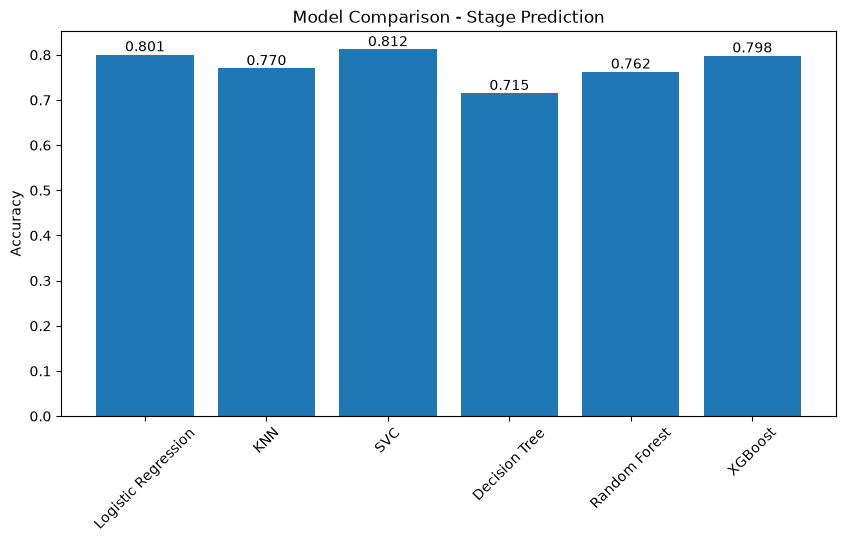

In [254]:
plt.figure(figsize=(10, 5))
bars = plt.bar(results_3.keys(), results_3.values())
plt.bar_label(bars, fmt='%.3f')
plt.xticks(rotation=45); plt.ylabel('Accuracy'); plt.title('Model Comparison - Stage Prediction')
plt.show()

In [255]:
joblib.dump(lr_3, 'survival_model.pkl')
joblib.dump(preprocessor_3, 'survival_preprocessor.pkl')
joblib.dump(le_3, 'survival_label_encoder.pkl')

['survival_label_encoder.pkl']

In [256]:
patient = df_3.loc[[X_3_test.index[0]]]

for task in ['organ', 'stage', 'survival']:
    model = joblib.load(f'{task}_model.pkl')
    prep = joblib.load(f'{task}_preprocessor.pkl')
    enc = joblib.load(f'{task}_label_encoder.pkl')
    print(f'Predicted {task}:', enc.inverse_transform(model.predict(prep.transform(patient)))[0])

print('\nActual:', patient['organ'].values[0], '|', patient['tumor_stage'].values[0], '|', patient['survival_status'].values[0])

Predicted organ: Breast
Predicted stage: STAGE II
Predicted survival: LIVING

Actual: Breast | STAGE IIIA | LIVING


In [257]:
def clean(x):
    x = x.strip()
    return 'Unknown' if x.lower() in ('', 'unknown') else x

# ---- manual input ----
patient = pd.DataFrame([{
    'age':               float(input('Age: ')),
    'sex':               clean(input('Sex (Male/Female): ')).title(),
    'histology_code':    clean(input('Histology code (e.g. 8500/3, or Unknown): ')),
    'tumor_stage':       clean(input('Tumor stage (e.g. STAGE II, or Unknown): ')).upper().replace('UNKNOWN', 'Unknown'),
    't_stage':           clean(input('T stage (e.g. T2, or Unknown): ')).upper().replace('UNKNOWN', 'Unknown'),
    'n_stage':           clean(input('N stage (e.g. N0, or Unknown): ')).upper().replace('UNKNOWN', 'Unknown'),
    'm_stage':           clean(input('M stage (e.g. M0, or Unknown): ')).upper().replace('UNKNOWN', 'Unknown'),
    'radiation_therapy': clean(input('Radiation therapy (Yes/No): ')).title(),
    'new_tumor_event':   clean(input('Cancer came back after treatment? (Yes/No): ')).title(),
}])

# ---- load saved models ----
m1, p1, e1 = joblib.load('organ_model.pkl'),    joblib.load('organ_preprocessor.pkl'),    joblib.load('organ_label_encoder.pkl')
m2, p2, e2 = joblib.load('stage_model.pkl'),    joblib.load('stage_preprocessor.pkl'),    joblib.load('stage_label_encoder.pkl')
m3, p3, e3 = joblib.load('survival_model.pkl'), joblib.load('survival_preprocessor.pkl'), joblib.load('survival_label_encoder.pkl')

# ---- 1. organ ----
organ = e1.inverse_transform(m1.predict(p1.transform(patient)))[0]
patient['organ'] = organ

# ---- 2. stage ----
stage = e2.inverse_transform(m2.predict(p2.transform(patient)))[0]
if patient['tumor_stage'][0] == 'Unknown':
    patient['tumor_stage'] = stage          # use predicted stage for survival

# ---- 3. survival ----
survival = e3.inverse_transform(m3.predict(p3.transform(patient)))[0]
death_risk = m3.predict_proba(p3.transform(patient))[0][list(e3.classes_).index('DECEASED')]

print('\n========== RESULT ==========')
print('Predicted cancer organ :', organ)
print('Predicted stage        :', stage)
print('Predicted survival     :', survival)
print(f'Risk of death          : {death_risk:.0%}')

ValueError: could not convert string to float: ''

In [ ]:
df['histology_code'].nunique()

130

In [258]:
%pip install catboost lightgbm xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 4.1 MB/s  0:00:23m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 3.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 4.5 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [catboost]3/4 [catboost]
Note: you may need to restart the kernel to use updated packages.


In [261]:
#Upgrading Accuracy using CatBoost, LightGBM, and XGBoost
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

In [262]:
def compare_boosters(X_train, y_train, X_test, y_test, prep):
    models = {
        'XGBoost':  XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42),
        'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
        'CatBoost': CatBoostClassifier(iterations=500, learning_rate=0.1, depth=6, random_seed=42, verbose=0),
    }
    results, pipes = {}, {}
    for name, model in models.items():
        pipe = Pipeline([('prep', clone(prep).set_params(sparse_threshold=0)),   # preprocessor + model in ONE object
                         ('model', model)])
        pipe.fit(X_train, y_train)
        pred = np.ravel(pipe.predict(X_test))
        results[name] = {'Accuracy': accuracy_score(y_test, pred),
                         'Macro F1': f1_score(y_test, pred, average='macro')}
        pipes[name] = pipe
        print(name, 'done')

    table = pd.DataFrame(results).T.sort_values('Accuracy', ascending=False)
    best = table.index[0]
    return table, pipes[best], best

In [263]:
table_1, best_pipe_1, best_name_1 = compare_boosters(X_1_train, y_1_train_encoded, X_1_test, y_1_test_encoded, preprocessor)
print('Best organ model:', best_name_1)
display(table_1)

joblib.dump({'model': best_pipe_1, 'labels': np.unique(y_1_train)}, 'organ_model.pkl')

XGBoost done
LightGBM done
CatBoost done
Best organ model: CatBoost


,Accuracy,Macro F1
CatBoost,0.927034,0.906572
XGBoost,0.926509,0.901646
LightGBM,0.915486,0.879551


['organ_model.pkl']

In [264]:
table_2, best_pipe_2, best_name_2 = compare_boosters(X_2_train, y_2_train_encoded, X_2_test, y_2_test_encoded, preprocessor_2)
print('Best stage model:', best_name_2)
display(table_2)

joblib.dump({'model': best_pipe_2, 'labels': np.unique(y_2_train)}, 'stage_model.pkl')

XGBoost done
LightGBM done
CatBoost done
Best stage model: CatBoost


,Accuracy,Macro F1
CatBoost,0.514262,0.489473
XGBoost,0.500839,0.476227
LightGBM,0.487416,0.471768


['stage_model.pkl']

In [265]:
table_3, best_pipe_3, best_name_3 = compare_boosters(X_3_train, y_3_train_encoded, X_3_test, y_3_test_encoded, preprocessor_3)
print('Best survival model:', best_name_3)
display(table_3)

joblib.dump({'model': best_pipe_3, 'labels': np.unique(y_3_train)}, 'survival_model.pkl')

XGBoost done
LightGBM done
CatBoost done
Best survival model: XGBoost


,Accuracy,Macro F1
XGBoost,0.800647,0.754313
LightGBM,0.795259,0.743458
CatBoost,0.781789,0.726746


['survival_model.pkl']

In [266]:
#preprocessing stage prediction part for better accuracy
X_2b = df_2.drop(columns=['patient_id', 'survival_status', 'survival_months',
                          'cancer_type', 'cancer_name', 'ethnicity', 'race',
                          'tumor_stage', 'stage'])          # t_stage, n_stage, m_stage now KEPT
y_2b = df_2['stage']

X_2b_train, X_2b_test, y_2b_train, y_2b_test = train_test_split(
    X_2b, y_2b, test_size=0.2, random_state=42, stratify=y_2b)

le_2b = LabelEncoder()
y_2b_train_enc = le_2b.fit_transform(y_2b_train)
y_2b_test_enc  = le_2b.transform(y_2b_test)

preprocessor_2b = ColumnTransformer([
    ('num', StandardScaler(), ['age']),
    ('cat', OneHotEncoder(handle_unknown='ignore'),
     ['sex', 'histology_code', 't_stage', 'n_stage', 'm_stage',
      'radiation_therapy', 'new_tumor_event', 'organ'])
])

In [267]:
table_2b, best_pipe_2b, best_name_2b = compare_boosters(X_2b_train, y_2b_train_enc,
                                                        X_2b_test, y_2b_test_enc, preprocessor_2b)
print('Best stage model (with TNM):', best_name_2b)
display(table_2b)

XGBoost done
LightGBM done
CatBoost done
Best stage model (with TNM): LightGBM


,Accuracy,Macro F1
LightGBM,0.962248,0.954874
CatBoost,0.961409,0.954232
XGBoost,0.958893,0.950871


In [268]:
pred = np.ravel(best_pipe_2b.predict(X_2b_test))
tnm_known = (X_2b_test['t_stage'] != 'Unknown').values

print('All test patients :', round(accuracy_score(y_2b_test_enc, pred), 3))
print('TNM known         :', round(accuracy_score(y_2b_test_enc[tnm_known],  pred[tnm_known]), 3), f'({tnm_known.sum()} patients)')
print('TNM unknown       :', round(accuracy_score(y_2b_test_enc[~tnm_known], pred[~tnm_known]), 3), f'({(~tnm_known).sum()} patients)')

All test patients : 0.962
TNM known         : 0.962 (1182 patients)
TNM unknown       : 1.0 (10 patients)


In [269]:
joblib.dump({'model': best_pipe_2b, 'labels': np.unique(y_2b_train)}, 'stage_model.pkl')

['stage_model.pkl']

In [270]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

cat_cols = [c for c in X_3_train.columns if c != 'age']     # every column except age is a category

surv_cat = CatBoostClassifier(iterations=800, learning_rate=0.05, depth=6,
                              cat_features=cat_cols, random_seed=42, verbose=0)
surv_cat.fit(X_3_train, y_3_train_encoded)                   # raw columns, no one-hot needed

pred  = surv_cat.predict(X_3_test).ravel()
proba = surv_cat.predict_proba(X_3_test)[:, 1]
print('Accuracy:', round(accuracy_score(y_3_test_encoded, pred), 4))
print('Macro F1:', round(f1_score(y_3_test_encoded, pred, average='macro'), 4))
print('ROC-AUC :', round(roc_auc_score(y_3_test_encoded, proba), 4))

Accuracy: 0.8087
Macro F1: 0.7649
ROC-AUC : 0.8641


In [276]:
joblib.dump({'model': surv_cat,
             'labels': np.unique(y_3_train),
             'columns': list(X_3_train.columns)},
            '../models/survival_catboost.pkl')

['../models/survival_catboost.pkl']

In [277]:
import joblib
for f in ['organ_catboost', 'stage_lightgbm_tnm', 'survival_catboost']:
    b = joblib.load(f'../models/{f}.pkl')
    model = b['model'].steps[-1][1] if hasattr(b['model'], 'steps') else b['model']
    print(f'{f:22s} → {type(model).__name__:22s} labels: {list(b["labels"])[:4]}...')

organ_catboost         → CatBoostClassifier     labels: ['Adrenal', 'Bladder', 'Blood/Lymph', 'Bone & Soft Tissue']...
stage_lightgbm_tnm     → LGBMClassifier         labels: ['STAGE I', 'STAGE II', 'STAGE III', 'STAGE IV']...
survival_catboost      → CatBoostClassifier     labels: ['DECEASED', 'LIVING']...
